# Paso 1 · Convertir las bases PISA 2025 a parquet

Pasar las bases de SPSS (`.sav` dentro de `.zip`) a archivos **parquet separados por país**, con todas las variables ()


## 1. Instalar librerías
Solo la primera vez. Si ya las tienes, salta esta celda.
- `pyreadstat` lee archivos SPSS.
- `pyarrow` escribe parquet.
- `inflate64` descomprime zips en formato *Deflate64* (el de estudiantes viene así y Python no lo abre por defecto).

In [1]:
%pip install pandas pyarrow pyreadstat inflate64

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Importar librerías

In [1]:
import json
import shutil
import time
from pathlib import Path

import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import pyreadstat
import struct
import zipfile
import inflate64

## 3. Definir rutas
El notebook busca la carpeta `Pisa` (donde están los zips).
- `SALIDA`: donde quedarán los parquet.
- `TEMPORAL`: donde se descomprime el `.sav` (se borra al final).

In [2]:
CARPETA_PISA = Path.cwd()
if not (CARPETA_PISA / "CY09_MS_STU_PUF.zip").exists():
    CARPETA_PISA = CARPETA_PISA.parent      # si el notebook está en /scripts

SALIDA = CARPETA_PISA / "datos"
TEMPORAL = CARPETA_PISA / "_temporal"

print("Carpeta PISA:", CARPETA_PISA)

Carpeta PISA: c:\Users\pauls\Desktop\Yachay\Pisa


## 4. Qué bases vamos a convertir
Nombre corto → archivo zip. Empezamos por las tres principales.

`FILAS_POR_PARTE`: cuántos estudiantes lee cada vez. Si sale `MemoryError`, bájalo a `10_000`.

In [ ]:
BASES = {
    "escuelas":    "CY09_MS_SCH_PUF.zip",
    "docentes":    "CY09_MS_TCH_PUF.zip",
    "estudiantes": "CY09_MS_STU_PUF.zip",
}

FILAS_POR_PARTE = 30_000

## 5. Funciones de apoyo

**`limpiar_texto`**: las columnas de texto se guardan siempre como texto. Así todas las partes tienen el mismo formato.

**`extraer_sav`**: descomprime el `.sav`. Si el zip es normal, lo hace Python. Si es *Deflate64* (tipo 9), salta la cabecera del zip y descomprime por bloques con `inflate64`.

**`guardar_etiquetas`**: el parquet no guarda las etiquetas de SPSS (ej. `1 = Female`). Las guardamos aparte en un `.json`.

In [5]:
def extraer_sav(archivo_zip, carpeta_destino):
    # Descomprime el .sav del zip. Soporta Deflate64 (zips grandes).
    with zipfile.ZipFile(archivo_zip) as z:
        info = [i for i in z.infolist() if i.filename.lower().endswith(".sav")][0]
        destino = Path(carpeta_destino) / Path(info.filename).name
        print(f"  Descomprimiendo {info.filename} ({info.file_size / 1e9:.1f} GB) ...")

        if info.compress_type != 9:          # zip normal: lo hace Python solo
            with z.open(info) as origen, open(destino, "wb") as salida:
                shutil.copyfileobj(origen, salida, 16 * 1024 * 1024)
            return destino

        # Deflate64 (tipo 9): lo descomprimimos con inflate64
        with open(archivo_zip, "rb") as f:
            f.seek(info.header_offset)
            cabecera = f.read(30)
            largo_nombre = struct.unpack("<H", cabecera[26:28])[0]
            largo_extra = struct.unpack("<H", cabecera[28:30])[0]
            f.seek(info.header_offset + 30 + largo_nombre + largo_extra)

            descompresor = inflate64.Inflater()
            restante = info.compress_size
            with open(destino, "wb") as salida:
                while restante > 0:
                    bloque = f.read(min(16 * 1024 * 1024, restante))
                    restante -= len(bloque)
                    salida.write(descompresor.inflate(bloque))
    return destino


def limpiar_texto(df):
    for col in df.columns:
        if df[col].dtype == object:
            df[col] = df[col].fillna("").astype(str)
    return df


def guardar_etiquetas(nombre, meta):
    def clave(k):
        return str(int(k)) if isinstance(k, float) and k.is_integer() else str(k)

    etiquetas = {
        "variables": meta.column_names_to_labels,
        "valores": {
            var: {clave(k): v for k, v in meta.value_labels[conj].items()}
            for var, conj in meta.variable_to_label.items()
        },
    }
    SALIDA.mkdir(exist_ok=True)
    with open(SALIDA / f"etiquetas_{nombre}.json", "w", encoding="utf-8") as f:
        json.dump(etiquetas, f, ensure_ascii=False, indent=1)

## 6. Función principal: `convertir`

Hace 4 cosas:
1. **Descomprime** el zip en `_temporal` (si el `.sav` ya está ahí, lo usa directo).
2. **Lee el `.sav` por partes** (`read_file_in_chunks`) para no llenar la memoria.
3. **Escribe cada parte en parquet**, separando por país (`partition_cols=["CNT"]`).
4. **Borra** el `.sav` temporal.

Detalle: la primera parte define los tipos de cada columna (`esquema`) y las demás se ajustan a ese mismo formato.

Nota: `pyreadstat` convierte los códigos de no respuesta (95–99) en vacíos (`NaN`) automáticamente.

In [6]:
def convertir(nombre, archivo_zip):
    inicio = time.time()
    print(f"=== {nombre} ({archivo_zip}) ===")

    destino = SALIDA / nombre
    if destino.exists():
        print("  Ya existe, lo salto. (Borra la carpeta si quieres rehacerlo)")
        return

    # 1. Descomprimir (si ya lo descomprimiste a mano en _temporal, lo usa directo)
    TEMPORAL.mkdir(exist_ok=True)
    ruta_sav = TEMPORAL / archivo_zip.replace(".zip", ".sav")
    if ruta_sav.exists():
        print(f"  Uso el .sav ya descomprimido: {ruta_sav.name}")
    else:
        ruta_sav = extraer_sav(CARPETA_PISA / archivo_zip, TEMPORAL)

    # 2 y 3. Leer por partes y escribir parquet por país
    esquema, total = None, 0
    lector = pyreadstat.read_file_in_chunks(
        pyreadstat.read_sav, str(ruta_sav), chunksize=FILAS_POR_PARTE
    )
    for i, (df, meta) in enumerate(lector):
        df = limpiar_texto(df)
        tabla = pa.Table.from_pandas(df, preserve_index=False)

        if esquema is None:
            esquema = tabla.schema
            guardar_etiquetas(nombre, meta)
        else:
            tabla = tabla.cast(esquema)

        pq.write_to_dataset(
            tabla,
            root_path=destino,
            partition_cols=["CNT"],
            basename_template=f"parte{i:04d}-{{i}}.parquet",
        )
        total += len(df)
        print(f"  {total:,} filas", end="\r")

    # 4. Borrar temporal
    ruta_sav.unlink()
    minutos = (time.time() - inicio) / 60
    print(f"\n  Listo: {total:,} filas, {len(df.columns)} variables, {minutos:.1f} min")

## 7. Probar con escuelas (la más pequeña)
Tarda segundos. Si funciona, seguimos con las demás.

In [7]:
convertir("escuelas", BASES["escuelas"])

=== escuelas (CY09_MS_SCH_PUF.zip) ===
  Ya existe, lo salto. (Borra la carpeta si quieres rehacerlo)


### Revisar: escuelas de Ecuador
Leemos solo Ecuador y 3 variables. Así se lee un parquet: eliges columnas (`columns`) y filtras filas (`filters`).
- `SC001Q01TA`: tamaño de la comunidad (1 = rural … 6 = megaciudad)
- `SC013Q01TA`: pública (1) o privada (2)

In [8]:
esc_ecu = pd.read_parquet(
    SALIDA / "escuelas",
    columns=["CNTSCHID", "SC001Q01TA", "SC013Q01TA"],
    filters=[("CNT", "==", "ECU")],
)
print(esc_ecu.shape)
esc_ecu["SC001Q01TA"].value_counts().sort_index()

(266, 3)


SC001Q01TA
1.0    44
2.0    40
3.0    54
4.0    83
5.0    41
6.0     4
Name: count, dtype: int64

## 8. Docentes y estudiantes

In [9]:
convertir("docentes", BASES["docentes"])

=== docentes (CY09_MS_TCH_PUF.zip) ===
  Ya existe, lo salto. (Borra la carpeta si quieres rehacerlo)


In [ ]:
# # Si falló a medias, borra la carpeta incompleta antes de reintentar
# shutil.rmtree(SALIDA / "estudiantes", ignore_errors=True)
# convertir("estudiantes", BASES["estudiantes"])

=== estudiantes (CY09_MS_STU_PUF.zip) ===
  Descomprimiendo CY09_MS_STU_PUF.sav (2.2 GB) ...
  755,721 filas
  Listo: 755,721 filas, 885 variables, 7.0 min


## 9. Limpiar y revisar
Borramos la carpeta temporal y vemos cuánto pesa cada base.

In [11]:
shutil.rmtree(TEMPORAL, ignore_errors=True)

for nombre in BASES:
    carpeta = SALIDA / nombre
    if carpeta.exists():
        mb = sum(f.stat().st_size for f in carpeta.rglob("*.parquet")) / 1e6
        paises = len(list(carpeta.glob("CNT=*")))
        print(f"{nombre:12s} {paises:3d} países  {mb:,.0f} MB")

escuelas      90 países  29 MB
docentes      19 países  11 MB
estudiantes   90 países  1,104 MB


### Revisar: estudiantes de Ecuador
Cuántos estudiantes hay y un vistazo a variables clave.

In [6]:
est_ecu = pd.read_parquet(
    SALIDA / "estudiantes",
    columns=["CNTSTUID", "ST004D01T", "ESCS", "PV1MATH", "W_FSTUWT"], # (sexo, nivel socioeconómico -0.98 std debajo de la OCDE, result mate, peso)
    filters=[("CNT", "==", "ECU")],
)
print(est_ecu.shape)
est_ecu.describe().round(2)

(9128, 5)


,ST004D01T,ESCS,PV1MATH,W_FSTUWT
count,9128.0,8831.00,9128.00,9128.00
mean,1.5,-0.98,370.23,29.35
std,0.5,1.08,64.16,15.99
min,1.0,-4.92,159.43,1.00
25%,1.0,-1.75,326.35,17.81
50%,1.0,-1.14,368.02,33.15
75%,2.0,-0.19,411.98,38.02
max,2.0,2.52,607.18,169.01


### Cómo usar las etiquetas
Ejemplo: qué significa cada valor de `ST004D01T` (sexo).

In [5]:
with open(SALIDA / "etiquetas_estudiantes.json", encoding="utf-8") as f:
    etiquetas = json.load(f)

print(etiquetas["variables"]["ST004D01T"])
etiquetas["valores"]["ST004D01T"]

Students' gender from sampling data (Female/Male)


{'1': 'Female',
 '2': 'Male',
 '95': 'valid skip (filter rule)',
 '96': 'system missing',
 '97': 'not administered/not applicable',
 '98': 'invalid',
 '99': 'no response'}

# Paso 2 · Puntajes y brechas en matemáticas: Ecuador vs. América Latina y la OCDE

**Pregunta general:** ¿cuánto rinde Ecuador en matemáticas y qué tan grandes son sus brechas de origen, comparado con otros países?

| Brecha | Grupo A | Grupo B | Pregunta que responder |
| --- | --- | --- | --- |
| Socioeconómica (`ESCS`) | 25 % más rico del país | 25 % más pobre del país | ¿Cuántos puntos más saca un estudiante de familia acomodada que uno de familia pobre en el mismo país? |
| Educación de los padres (`HISCED`) | con educación superior (ISCED 5 o más) | sin educación superior | ¿Cuánto pesa que los padres tengan estudios superiores en el aprendizaje de sus hijos? |
| Sexo (`MALE`) | hombres | mujeres (u otra categoría) | ¿Los hombres y las mujeres aprenden lo mismo en matemáticas, o hay una diferencia por sexo? |
| Zona (`SC001Q01TA`, base de escuelas) | ciudad (más de 100 mil hab.) | zona rural (menos de 3 mil hab.) | ¿Cuánto influye estudiar en el campo o en la ciudad? |


**Validación:** el promedio OCDE (≈ 463) y la brecha OCDE por sexo (≈ 13 puntos) deben coincidir con las cifras oficiales de *PISA 2025 Results, Volume I* (OCDE, 2026).

## 1. Importar librerías

In [7]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Rutas y países

- `LATAM`: los 13 países de América Latina en PISA 2025.
- Además traemos **todos los países OCDE** (`OECD` = 1) para calcular el promedio OCDE.

In [8]:
CARPETA_PISA = Path.cwd()
if not (CARPETA_PISA / "datos").exists():
    CARPETA_PISA = CARPETA_PISA.parent      # si el notebook está en /scripts
DATOS = CARPETA_PISA / "datos"

LATAM = ["ARG", "BRA", "CHL", "COL", "CRI", "DOM", "ECU",
         "GTM", "MEX", "PER", "PRY", "SLV", "URY"]

## 3. Elegir columnas

Solo leemos lo necesario (así es rápido):
- `PV`: los 10 valores plausibles de matemáticas.
- `PESO`: el peso final. `REPS`: los 80 pesos replicados (para el error estándar).

In [9]:
PV   = [f"PV{i}MATH" for i in range(1, 11)]
PESO = "W_FSTUWT"
REPS = [f"W_FSTURWT{r}" for r in range(1, 81)]

COLUMNAS = ["CNT", "CNTSCHID", "OECD", "MALE", "ESCS", "HISCED"] + PV + [PESO] + REPS
len(COLUMNAS)

97

## 4. Leer estudiantes

`filters` con dos listas = condición **"o"**: países de América Latina **o** países OCDE.
Pasamos los números a `float32` para ahorrar memoria.

In [10]:
est = pd.read_parquet(
    DATOS / "estudiantes",
    columns=COLUMNAS,
    filters=[[("CNT", "in", LATAM)], [("OECD", "==", 1.0)]],
)
est["CNT"] = est["CNT"].astype(str)
num = est.select_dtypes("float64").columns
est[num] = est[num].astype("float32")

print(est.shape)
est["CNT"].nunique()

(406911, 97)


47

## 5. Unir con la base de escuelas (zona rural/urbana)

La zona viene del cuestionario del director (`SC001Q01TA`). La pegamos a cada estudiante usando país + escuela (`CNT`, `CNTSCHID`).

`how="left"` = conservamos todos los estudiantes aunque su escuela no tenga dato.

In [11]:
esc = pd.read_parquet(DATOS / "escuelas", columns=["CNT", "CNTSCHID", "SC001Q01TA"])
esc["CNT"] = esc["CNT"].astype(str)

est = est.merge(esc, on=["CNT", "CNTSCHID"], how="left")

print("Estudiantes sin dato de zona:", f"{est['SC001Q01TA'].isna().mean():.1%}")

Estudiantes sin dato de zona: 14.4%


## 5.1. Revisión de los datos (calidad + EDA)

Antes de calcular brechas, miramos **qué hay** en los datos. Dos partes:

- **A. Calidad:** ¿están completos?, ¿hay valores raros?, ¿qué falta y dónde?
- **B. Exploración (EDA):** ¿cómo se distribuyen los puntajes y el nivel socioeconómico?

Nota: en la parte B usamos **pesos** pero **un solo valor plausible** (`PV1MATH`). Es suficiente para explorar; los resultados formales (sección 7 en adelante) usan los 10.

### A1. Estructura general

Cuántos estudiantes y países tenemos, y si hay estudiantes repetidos. Para revisar repetidos leemos el ID del estudiante (`CNTSTUID`) aparte.

In [12]:
print(f"Estudiantes: {len(est):,}")
print(f"Países:      {est['CNT'].nunique()}  ({est['CNT'].isin(LATAM).groupby(est['CNT']).first().sum()} de América Latina)")

ids = pd.read_parquet(
    DATOS / "estudiantes",
    columns=["CNT", "CNTSTUID"],
    filters=[[("CNT", "in", LATAM)], [("OECD", "==", 1.0)]],
)
print(f"Estudiantes repetidos: {ids.duplicated().sum()}")

Estudiantes: 406,911
Países:      47  (13 de América Latina)
Estudiantes repetidos: 0


### A2. Ficha de cada variable

Para cada variable: cuántos datos válidos tiene, qué % falta, su mínimo y máximo, y si está **dentro del rango esperado** según el codebook. Si algo sale fuera de rango, hay que limpiarlo.

In [ ]:
RANGOS = {                        # rango válido según el codebook
    "PV1MATH":    (0, 1000),
    PESO:         (0, None),      # el peso debe ser positivo W_FSTUWT
    "MALE":       (0, 1), #
    "ESCS":       (-8, 6), #Índice socioeconómico y cultural
    "HISCED":     (1, 9), #educación más alta de los padres
    "SC001Q01TA": (1, 6), #tamaño de la comunidad de la escuela
}

ficha = []
for col, (lo, hi) in RANGOS.items():
    x = est[col]
    fuera = ((x < lo) if lo is not None else False) | ((x > hi) if hi is not None else False)
    ficha.append({
        "variable": col,
        "válidos": x.notna().sum(),
        "% faltante": round(100 * x.isna().mean(), 1),
        "mínimo": float(x.min()),
        "máximo": float(x.max()),
        "fuera de rango": int(fuera.sum()),
    })
pd.DataFrame(ficha).set_index("variable").round(2)

,válidos,% faltante,mínimo,máximo,fuera de rango
variable,,,,,
PV1MATH,406910,0.0,62.76,897.14,0
W_FSTUWT,406911,0.0,1.00,5828.96,0
MALE,406896,0.0,0.00,1.00,0
ESCS,362360,10.9,-5.71,4.55,0
HISCED,345380,15.1,1.00,9.00,0
SC001Q01TA,348147,14.4,1.00,6.00,0


### A3. ¿Dónde faltan datos? (% por país)

Los faltantes no se reparten igual: algunos países no aplicaron una pregunta. Tabla para América Latina + el promedio de los países OCDE. Más oscuro = más faltantes.

In [14]:
VARS = {"ESCS": "ESCS", "HISCED": "Padres", "MALE": "Sexo", "SC001Q01TA": "Zona"}

faltan = (est.groupby("CNT")[list(VARS)].agg(lambda s: 100 * s.isna().mean())
             .rename(columns=VARS).round(1))

tabla_faltan = faltan.loc[faltan.index.isin(LATAM)].copy()
ocde_ids = est.loc[est["OECD"] == 1, "CNT"].unique()
tabla_faltan.loc["Promedio OCDE"] = faltan.loc[ocde_ids].mean().round(1)

tabla_faltan.style.background_gradient(cmap="Blues", vmin=0, vmax=100).format("{:.1f}")

,ESCS,Padres,Sexo,Zona
CNT,,,,
ARG,11.6,18.1,0.0,15.3
BRA,9.0,11.8,0.0,5.8
CHL,9.1,11.1,0.0,13.3
COL,6.0,9.4,0.0,2.5
CRI,100.0,100.0,0.0,3.6
DOM,9.7,15.9,0.0,14.2
ECU,3.3,6.7,0.0,0.0
GTM,10.4,14.1,0.0,4.5
MEX,2.2,4.8,0.0,1.4


### A4. ¿Los que faltan son distintos?

Si los estudiantes **sin** `ESCS` rinden menos que los que sí tienen, al excluirlos la brecha puede salir más chica de lo real (sesgo). Comparamos su puntaje promedio (con pesos).

In [15]:
def media_w(x, w):
    ok = x.notna()
    return np.average(x[ok], weights=w[ok]) if ok.any() else np.nan

filas = []
for pais, g in est[est["CNT"].isin(LATAM)].groupby("CNT"):
    falta = g["ESCS"].isna()
    if falta.mean() in (0, 1):          # no hay con quién comparar
        continue
    filas.append({
        "país": pais,
        "% sin ESCS": round(100 * falta.mean(), 1),
        "puntaje CON ESCS": round(media_w(g.loc[~falta, "PV1MATH"], g.loc[~falta, PESO])),
        "puntaje SIN ESCS": round(media_w(g.loc[falta, "PV1MATH"], g.loc[falta, PESO])),
    })
sesgo = pd.DataFrame(filas).set_index("país")
sesgo["diferencia"] = sesgo["puntaje SIN ESCS"] - sesgo["puntaje CON ESCS"]
sesgo

,% sin ESCS,puntaje CON ESCS,puntaje SIN ESCS,diferencia
país,,,,
ARG,11.6,373,336,-37
BRA,9.0,382,312,-70
CHL,9.1,406,369,-37
COL,6.0,385,314,-71
DOM,9.7,342,314,-28
ECU,3.3,367,334,-33
GTM,10.4,338,296,-42
MEX,2.2,389,334,-55
PER,4.9,384,330,-54


Resultados negativos = los que no tienen `ESCS` rinden menos, el `% sin ESCS` es pequeño (< 10 %), 

### B1. Distribución del puntaje en matemáticas por país

Para cada país: **punto** = mediana; **barra gruesa** = 50 % central (percentiles 25–75); **barra delgada** = 80 % central (percentiles 10–90). Ecuador en azul.

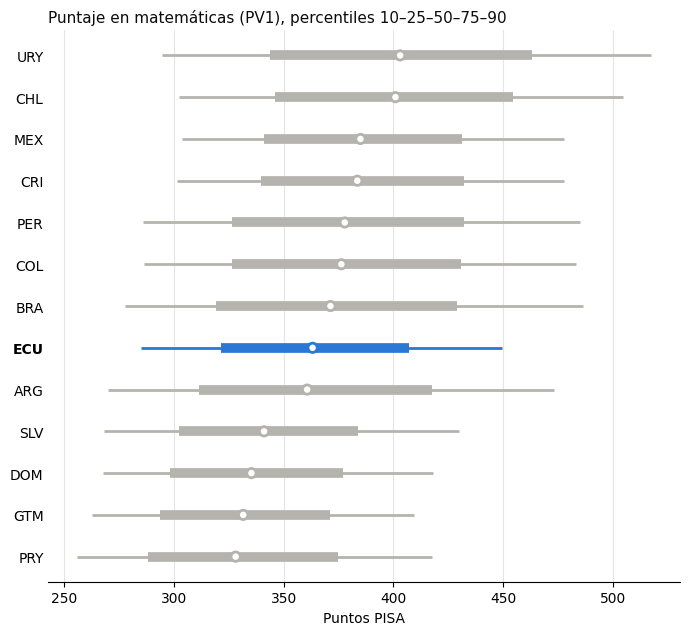

,p10,p25,p50,p75,p90
pais,,,,,
PRY,255.800003,288.200012,328.000000,374.700012,417.600006
GTM,262.600006,293.600006,331.500000,371.200012,409.299988
DOM,267.299988,298.299988,335.200012,376.899994,418.000000
SLV,268.000000,302.399994,341.000000,383.799988,430.000000
ARG,270.000000,311.100006,360.600006,417.799988,473.299988
ECU,285.100006,321.200012,363.100006,407.000000,449.600006
BRA,277.700012,319.000000,371.299988,429.100006,486.500000
COL,286.399994,326.299988,376.200012,430.899994,483.200012
PER,285.799988,326.200012,377.799988,432.299988,485.100006


In [16]:
AZUL, GRIS, TINTA, TENUE = "#2a78d6", "#b5b3ad", "#0b0b0b", "#898781"

def percentiles_w(x, w, qs=(0.10, 0.25, 0.50, 0.75, 0.90)):
    ok = x.notna()
    x, w = x[ok].to_numpy(), w[ok].to_numpy()
    orden = np.argsort(x)
    acum = np.cumsum(w[orden]) / w.sum()
    return [x[orden][min(np.searchsorted(acum, q), len(x) - 1)] for q in qs]


def grafico_distribucion(col, titulo, xlabel):
    filas = []
    for pais, g in est[est["CNT"].isin(LATAM)].groupby("CNT"):
        if g[col].notna().any():
            filas.append([pais] + percentiles_w(g[col], g[PESO]))
    d = pd.DataFrame(filas, columns=["pais", "p10", "p25", "p50", "p75", "p90"]).sort_values("p50")

    fig, ax = plt.subplots(figsize=(7, 0.42 * len(d) + 1))
    y = np.arange(len(d))
    color = [AZUL if p == "ECU" else GRIS for p in d["pais"]]
    ax.hlines(y, d["p10"], d["p90"], color=color, lw=2)
    ax.hlines(y, d["p25"], d["p75"], color=color, lw=7)
    ax.scatter(d["p50"], y, color="white", edgecolor=color, s=45, zorder=3, lw=2)
    ax.set_yticks(y, d["pais"])
    for t in ax.get_yticklabels():
        t.set_fontweight("bold" if t.get_text() == "ECU" else "normal")
    ax.set_title(titulo, loc="left", fontsize=11, color=TINTA)
    ax.set_xlabel(xlabel)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", color="#e5e4e0", lw=0.8)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()
    return d.set_index("pais").round(1)

grafico_distribucion("PV1MATH", "Puntaje en matemáticas (PV1), percentiles 10–25–50–75–90", "Puntos PISA")

### B2. Distribución del nivel socioeconómico (`ESCS`) por país

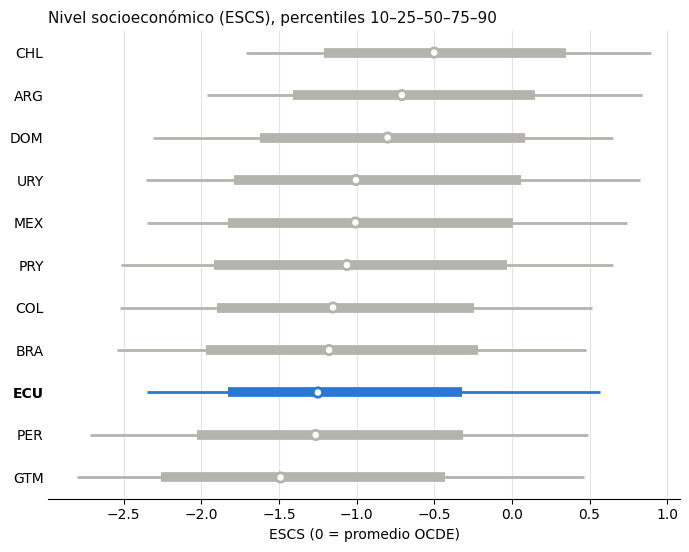

,p10,p25,p50,p75,p90
pais,,,,,
GTM,-2.8,-2.3,-1.5,-0.4,0.5
PER,-2.7,-2.0,-1.3,-0.3,0.5
ECU,-2.4,-1.8,-1.2,-0.3,0.6
BRA,-2.5,-2.0,-1.2,-0.2,0.5
COL,-2.5,-1.9,-1.2,-0.2,0.5
PRY,-2.5,-1.9,-1.1,-0.0,0.7
MEX,-2.4,-1.8,-1.0,0.0,0.7
URY,-2.4,-1.8,-1.0,0.1,0.8
DOM,-2.3,-1.6,-0.8,0.1,0.7


In [17]:
grafico_distribucion("ESCS", "Nivel socioeconómico (ESCS), percentiles 10–25–50–75–90", "ESCS (0 = promedio OCDE)")

### B3. ¿Cómo es la población de Ecuador?

Porcentaje de estudiantes en cada categoría, **con pesos** (= % de la población de 15 años, no de la muestra).

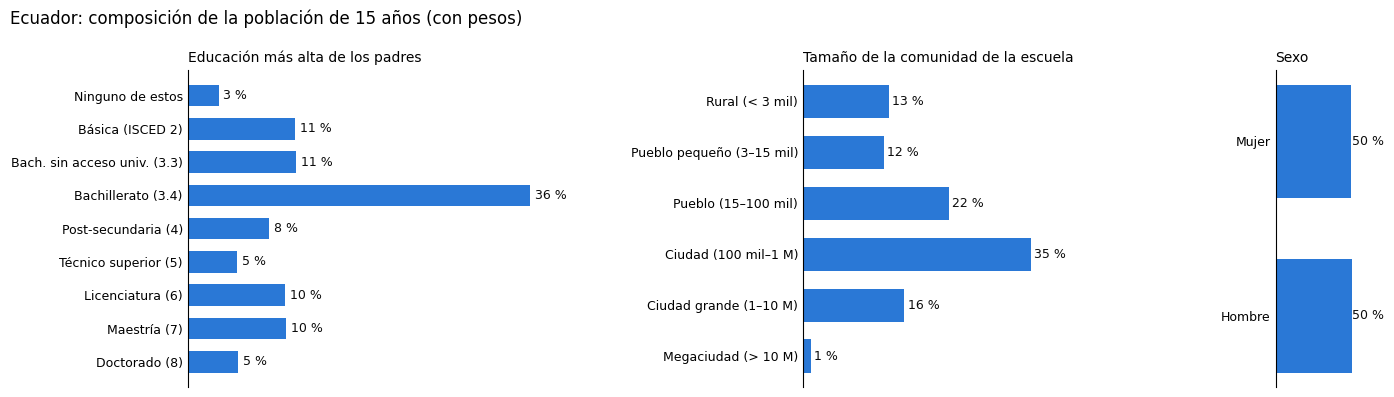

In [19]:
def porcentaje_w(col, etiquetas_cat):
    g = ecu_todos[[col, PESO]].dropna()
    p = g.groupby(col)[PESO].sum() / g[PESO].sum() * 100
    p.index = [etiquetas_cat.get(int(k), k) for k in p.index]
    return p.round(1)

ecu_todos = est[est["CNT"] == "ECU"]

comp = {
    "Educación más alta de los padres": porcentaje_w("HISCED", {
        1: "Ninguno de estos", 2: "Básica (ISCED 2)", 3: "Bach. sin acceso univ. (3.3)",
        4: "Bachillerato (3.4)", 5: "Post-secundaria (4)", 6: "Técnico superior (5)",
        7: "Licenciatura (6)", 8: "Maestría (7)", 9: "Doctorado (8)"}),
    "Tamaño de la comunidad de la escuela": porcentaje_w("SC001Q01TA", {
        1: "Rural (< 3 mil)", 2: "Pueblo pequeño (3–15 mil)", 3: "Pueblo (15–100 mil)",
        4: "Ciudad (100 mil–1 M)", 5: "Ciudad grande (1–10 M)", 6: "Megaciudad (> 10 M)"}),
    "Sexo": porcentaje_w("MALE", {0: "Mujer", 1: "Hombre"}),
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4), gridspec_kw={"width_ratios": [9, 6, 2]})
for ax, (titulo, p) in zip(axes, comp.items()):
    ax.barh(range(len(p)), p.values, color=AZUL, height=0.65)
    ax.set_yticks(range(len(p)), p.index, fontsize=9)
    ax.invert_yaxis()
    for i, v in enumerate(p.values):
        ax.text(v + 0.5, i, f"{v:.0f} %", va="center", fontsize=9, color=TINTA)
    ax.set_title(titulo, loc="left", fontsize=10)
    ax.set_xlim(0, p.max() * 1.25)
    ax.set_xticks([])
    ax.spines[["top", "right", "bottom"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
fig.suptitle("Ecuador: composición de la población de 15 años (con pesos)", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

## 6. Crear los grupos de comparación

**Quintiles/cuartiles de ESCS con pesos:** el 25 % más pobre y más rico se calcula **dentro de cada país** y usando el peso, para que represente a la población y no a la muestra.

Cada grupo queda como 1 (grupo A), 0 (grupo B) o vacío (no entra en esa brecha).

**Ojo con el sexo:** `ST004D01T` viene vacío en algunos países (p. ej. Chile y Colombia). Por eso usamos `MALE`, que está completa en todos.

In [20]:
def cuantil_ponderado(x, w, q):
    # Ordena x y busca el valor donde el peso acumulado llega a q
    ok = ~np.isnan(x) & ~np.isnan(w)
    x, w = x[ok], w[ok]
    if len(x) == 0:                      # país sin datos de ESCS
        return np.nan
    orden = np.argsort(x)
    acumulado = np.cumsum(w[orden]) / w.sum()
    i = min(np.searchsorted(acumulado, q), len(x) - 1)
    return x[orden][i]


def cuartil_escs(g):
    x, w = g["ESCS"].to_numpy(), g[PESO].to_numpy()
    q25, q75 = cuantil_ponderado(x, w, 0.25), cuantil_ponderado(x, w, 0.75)
    return pd.Series(np.select([x <= q25, x >= q75], [0, 1], np.nan), index=g.index)


est["g_escs"] = est.groupby("CNT", group_keys=False)[["ESCS", PESO]].apply(cuartil_escs)
est["g_padres"] = np.select([est["HISCED"] >= 6, est["HISCED"] <= 5], [1, 0], np.nan)
est["g_sexo"] = est["MALE"]            # ya es 1 = hombre, 0 = mujer
est["g_zona"] = np.select([est["SC001Q01TA"] >= 4, est["SC001Q01TA"] == 1], [1, 0], np.nan)

est[["g_escs", "g_padres", "g_sexo", "g_zona"]].describe().loc[["count", "mean"]].round(2)

,g_escs,g_padres,g_sexo,g_zona
count,180998.00,345380.00,406896.0,167608.00
mean,0.51,0.58,0.5,0.84


## 7. La función clave: estimar como lo hace la OCDE

Con PISA no basta un promedio simple. Hacemos 3 cosas:

1. **Pesos:** cada estudiante cuenta según `W_FSTUWT`.
2. **10 valores plausibles:** calculamos el estadístico 10 veces (una por PV) y promediamos.
3. **Error estándar:** combina dos incertidumbres:
   - *de muestreo*: repetimos el cálculo con los 80 pesos replicados;
   - *de medición*: cuánto varían los 10 PV entre sí.

```latex
SE = \sqrt{\underbrace{\tfrac{1}{20}\sum_{r=1}^{80}(\hat\theta_r-\hat\theta)^2}_{\text{muestreo}} + \underbrace{\left(1+\tfrac{1}{10}\right)\,\mathrm{Var}(\hat\theta_{PV})}_{\text{medición}}}
```

El `1/20` viene del método BRR-Fay que usa PISA: 1 / (80 × 0,5²).

La función `estimar` sirve para **cualquier** estadístico: le pasamos una función que recibe los puntajes y un peso.

In [21]:
def media(Y, w):
    # Promedio ponderado de cada columna de Y (una por PV)
    return (w @ Y) / w.sum()


def estimar(df, estadistico):
    Y = df[PV].to_numpy("float64")
    w = df[PESO].to_numpy("float64")
    W = df[REPS].to_numpy("float64")

    est_pv = estadistico(Y, w)                                      # 10 valores
    est_rep = np.array([estadistico(Y, W[:, r]) for r in range(80)])  # 80 x 10

    var_muestreo = (0.05 * ((est_rep - est_pv) ** 2).sum(axis=0)).mean()
    var_medicion = (1 + 1 / 10) * est_pv.var(ddof=1)
    return est_pv.mean(), np.sqrt(var_muestreo + var_medicion)


def brecha(df, grupo):
    # Promedio del grupo A (=1) menos promedio del grupo B (=0)
    a = (df[grupo] == 1).to_numpy()
    b = (df[grupo] == 0).to_numpy()
    return estimar(df, lambda Y, w: media(Y[a], w[a]) - media(Y[b], w[b]))

### Prueba rápida con Ecuador

Ahora sí: promedio de matemáticas **bien calculado** (con pesos y los 10 PV) y su error estándar.

In [22]:
ecu = est[est["CNT"] == "ECU"]
m, se = estimar(ecu, media)
print(f"Ecuador, matemáticas: {m:.1f} puntos (error estándar {se:.1f})")

Ecuador, matemáticas: 365.8 puntos (error estándar 1.7)


## 8. Calcular para todos los países

Un bucle: para cada país, el promedio y las 4 brechas. Tarda un poco (son muchos cálculos con los 80 pesos).

In [25]:
BRECHAS = {"g_escs": "ESCS", "g_padres": "Padres", "g_sexo": "Sexo", "g_zona": "Zona"}

filas = []
for pais, df in est.groupby("CNT"):
    fila = {"pais": pais, "oecd": df["OECD"].iloc[0] == 1, "latam": pais in LATAM}
    fila["media"], fila["media_se"] = estimar(df, media)
    for col, nombre in BRECHAS.items():
        n_a, n_b = (df[col] == 1).sum(), (df[col] == 0).sum()
        if min(n_a, n_b) < 30:             # muy pocos casos: no se reporta
            fila[nombre], fila[nombre + "_se"] = np.nan, np.nan
        else:
            fila[nombre], fila[nombre + "_se"] = brecha(df, col)
    filas.append(fila)

res = pd.DataFrame(filas)
res.head(3)

,pais,oecd,latam,media,media_se,ESCS,ESCS_se,Padres,Padres_se,Sexo,Sexo_se,Zona,Zona_se
0,ARG,False,True,366.814203,2.663461,79.001429,5.398333,38.974161,3.685507,19.077829,2.205283,29.833591,12.355901
1,AUS,True,False,477.526651,1.915162,82.067291,3.595590,52.564325,2.838043,16.411269,2.247602,37.917926,11.263350
2,AUT,True,False,477.193866,2.575795,81.430826,3.585750,39.732379,2.921260,22.746512,3.335903,5.462888,21.345124


## 9. Promedio OCDE

La OCDE calcula su promedio como el **promedio simple de sus países** (cada país pesa igual). Su error estándar: raíz de la suma de varianzas, dividida para el número de países.

In [24]:
ocde = res[res["oecd"]]
fila_ocde = {"pais": "OCDE", "oecd": True, "latam": False}
for c in ["media"] + list(BRECHAS.values()):
    validos = ocde[[c, c + "_se"]].dropna()
    if validos.empty:
        fila_ocde[c], fila_ocde[c + "_se"] = np.nan, np.nan
        continue
    fila_ocde[c] = validos[c].mean()
    fila_ocde[c + "_se"] = np.sqrt((validos[c + "_se"] ** 2).sum()) / len(validos)

tabla = pd.concat([res[res["latam"]], pd.DataFrame([fila_ocde])], ignore_index=True)
tabla = tabla.sort_values("media", ascending=False).reset_index(drop=True)
tabla

,pais,oecd,latam,media,media_se,ESCS,ESCS_se,Padres,Padres_se,Sexo,Sexo_se,Zona,Zona_se
0,OCDE,True,False,462.570368,0.429652,82.965183,0.875704,49.868909,0.617448,13.134277,0.542637,32.985707,2.933082
1,URY,False,True,404.878846,1.945176,93.383637,4.189253,59.331555,3.226122,13.717390,2.323995,49.846833,8.886322
2,CHL,True,True,402.645223,2.176102,69.683777,4.454052,40.625960,2.997317,17.651400,2.399212,22.145386,21.165101
3,MEX,True,True,387.587171,1.858169,57.189954,3.559214,31.352441,2.791500,15.795292,1.842403,51.604091,5.752573
4,CRI,True,True,387.091245,2.250974,NaN,NaN,NaN,NaN,22.310644,2.447762,22.362108,8.610657
5,PER,False,True,382.439375,2.448291,74.437613,4.257948,40.047009,3.388341,12.803467,2.994043,56.496818,9.941190
6,COL,True,True,380.528674,2.781410,78.113702,5.984440,43.619067,3.971524,13.554013,2.321236,52.784925,6.942057
7,BRA,False,True,376.767936,1.748012,90.409522,3.382080,47.964181,2.430177,7.363731,1.747955,62.783935,7.701834
8,ARG,False,True,366.814203,2.663461,79.001429,5.398333,38.974161,3.685507,19.077829,2.205283,29.833591,12.355901
9,ECU,False,True,365.839357,1.721706,67.965201,3.913270,41.422892,3.207450,12.188016,1.650408,33.907015,6.575108


## 10. Tabla final legible

Formato "valor (error estándar)". Una brecha es **estadísticamente distinta de cero** si su valor es mayor que ~2 veces su error estándar (lo marcamos con `*`).

In [26]:
def fmt(v, se, marcar=True):
    if pd.isna(v):
        return "—"
    signif = "*" if marcar and abs(v) > 1.96 * se else ""
    return f"{v:.0f} ({se:.1f}){signif}"

legible = pd.DataFrame({"País": tabla["pais"]})
legible["Matemáticas"] = [fmt(v, s, marcar=False) for v, s in zip(tabla["media"], tabla["media_se"])]
for n in BRECHAS.values():
    legible[f"Brecha {n}"] = [fmt(v, s) for v, s in zip(tabla[n], tabla[n + "_se"])]
legible

,País,Matemáticas,Brecha ESCS,Brecha Padres,Brecha Sexo,Brecha Zona
0,OCDE,463 (0.4),83 (0.9)*,50 (0.6)*,13 (0.5)*,33 (2.9)*
1,URY,405 (1.9),93 (4.2)*,59 (3.2)*,14 (2.3)*,50 (8.9)*
2,CHL,403 (2.2),70 (4.5)*,41 (3.0)*,18 (2.4)*,22 (21.2)
3,MEX,388 (1.9),57 (3.6)*,31 (2.8)*,16 (1.8)*,52 (5.8)*
4,CRI,387 (2.3),—,—,22 (2.4)*,22 (8.6)*
5,PER,382 (2.4),74 (4.3)*,40 (3.4)*,13 (3.0)*,56 (9.9)*
6,COL,381 (2.8),78 (6.0)*,44 (4.0)*,14 (2.3)*,53 (6.9)*
7,BRA,377 (1.7),90 (3.4)*,48 (2.4)*,7 (1.7)*,63 (7.7)*
8,ARG,367 (2.7),79 (5.4)*,39 (3.7)*,19 (2.2)*,30 (12.4)*
9,ECU,366 (1.7),68 (3.9)*,41 (3.2)*,12 (1.7)*,34 (6.6)*


## 11. Gráfico 1: promedio en matemáticas

Punto = promedio; línea horizontal = intervalo de confianza al 95 % (± 1,96 × error estándar). Ecuador en azul; la línea punteada es el promedio OCDE.

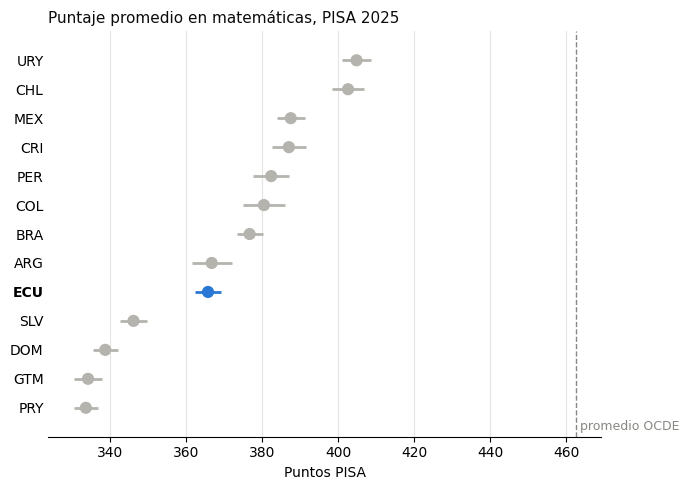

In [27]:
AZUL, GRIS, TINTA, TENUE = "#2a78d6", "#b5b3ad", "#0b0b0b", "#898781"

def grafico_puntos(ax, datos, col, titulo):
    datos = datos[datos["pais"] != "OCDE"].dropna(subset=[col]).sort_values(col)
    y = np.arange(len(datos))
    colores = [AZUL if p == "ECU" else GRIS for p in datos["pais"]]
    ax.errorbar(datos[col], y, xerr=1.96 * datos[col + "_se"], fmt="none",
                ecolor=colores, elinewidth=2, capsize=0)
    ax.scatter(datos[col], y, c=colores, s=60, zorder=3)
    ref = fila_ocde[col]
    ax.axvline(ref, color=TENUE, ls="--", lw=1)
    ax.text(ref, 0.01, " promedio OCDE", color=TENUE, fontsize=9,
            transform=ax.get_xaxis_transform(), va="bottom")
    ax.set_yticks(y, datos["pais"])
    ax.set_ylim(-1, len(datos))
    for t in ax.get_yticklabels():
        if t.get_text() == "ECU":
            t.set_fontweight("bold")
    ax.set_title(titulo, loc="left", fontsize=11, color=TINTA)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", color="#e5e4e0", lw=0.8)
    ax.set_axisbelow(True)

fig, ax = plt.subplots(figsize=(7, 5))
grafico_puntos(ax, tabla, "media", "Puntaje promedio en matemáticas, PISA 2025")
ax.set_xlabel("Puntos PISA")
plt.tight_layout()
plt.show()

## 11. Gráfico 1: las 4 brechas

Cada panel ordena los países de menor a mayor brecha. Ojo: **los ejes son distintos** en cada panel (las brechas tienen tamaños diferentes).

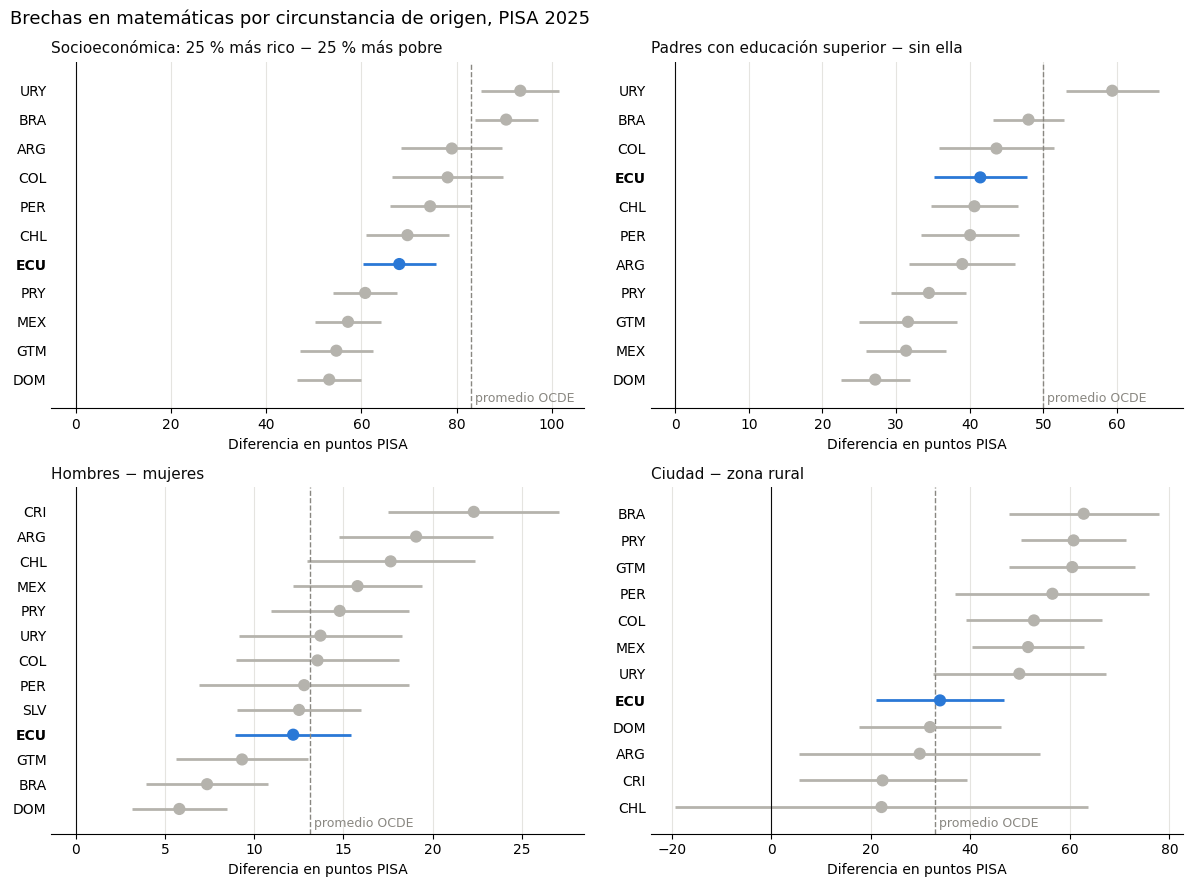

In [28]:
titulos = {
    "ESCS": "Socioeconómica: 25 % más rico − 25 % más pobre",
    "Padres": "Padres con educación superior − sin ella",
    "Sexo": "Hombres − mujeres",
    "Zona": "Ciudad − zona rural",
}
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (col, titulo) in zip(axes.flat, titulos.items()):
    grafico_puntos(ax, tabla, col, titulo)
    ax.axvline(0, color=TINTA, lw=0.8)
    ax.set_xlabel("Diferencia en puntos PISA")
fig.suptitle("Brechas en matemáticas por circunstancia de origen, PISA 2025",
             x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()

## 12. Respuestas a las preguntas

**1. Brecha socioeconómica (`ESCS`)**
*¿Cuántos puntos más saca un estudiante de familia acomodada que uno de familia pobre en el mismo país?*

En Ecuador, el 25 % más rico saca **68 puntos más** que el 25 % más pobre (± 8). La brecha es real (no toca el 0). Es **menor** que la de la OCDE (83 puntos) y está en la mitad baja de la región: puesto 7 de 11, lejos de Uruguay (93) y Brasil (90). 

**2. Educación de los padres (`HISCED`)**
*¿Cuánto pesa que los padres tengan estudios superiores en el aprendizaje de sus hijos?*

Los hijos de padres con educación superior sacan **41 puntos más** (± 6). La brecha es real. Es **menor** que la de la OCDE (50 puntos), pero de las más altas de la región: puesto 4 de 11, solo detrás de Uruguay (59), Brasil (48) y Colombia (44).

**3. Sexo (`MALE`)**
*¿Los hombres y las mujeres aprenden lo mismo en matemáticas, o hay una diferencia por sexo?*

Los hombres sacan **12 puntos más** que las mujeres (± 3). La diferencia es real, pero pequeña. Es **similar** a la de la OCDE (13 puntos, sin diferencia significativa) y de las más bajas de la región: puesto 10 de 13. En los 13 países de América Latina los hombres superan a las mujeres en matemáticas.

**4. Zona (`SC001Q01TA`)**
*¿Cuánto influye estudiar en el campo o en la ciudad?*

Los estudiantes de ciudad sacan **34 puntos más** que los de zona rural (± 13). La brecha es real, pero es la menos precisa (pocos estudiantes rurales). Es **similar** a la de la OCDE (33 puntos) y está en la mitad baja de la región: puesto 8 de 12, lejos de Brasil (63), Paraguay (61) y Guatemala (60).

**En resumen:** en Ecuador, la circunstancia que más pesa es el **nivel socioeconómico (68)**, seguida de la **educación de los padres (41)**, la **zona (34)** y, muy por detrás, el **sexo (12)**.

## 13. Guardar resultados

Guardamos la tabla completa (con errores estándar) para usarla después.

In [34]:
salida = DATOS / "resultados"
salida.mkdir(exist_ok=True)
tabla.to_csv(salida / "paso3_matematicas_brechas.csv", index=False)
print("Guardado en", salida / "paso3_matematicas_brechas.csv")

Guardado en c:\Users\pauls\Desktop\Yachay\Pisa\datos\resultados\paso3_matematicas_brechas.csv


**Listo el paso 3.** Para leer los resultados: compara la brecha de Ecuador con la de otros países y con la OCDE. Una brecha grande = el origen pesa mucho en el aprendizaje. Siguiente paso: medir la **desigualdad de oportunidades** (qué parte de la desigualdad total explican las circunstancias).